<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

**公司名称：** 宁德时代新能源科技股份有限公司（简称"宁德时代"）

**股票代码：** 300750.SZ（深圳证券交易所创业板）

**上市时间：** 2018年6月11日

**主营业务：** 公司专注于新能源汽车动力电池系统、储能系统的研发、生产与销售，同时布局电池材料（正极材料、负极材料、电解液等）与电池回收利用业务，业务链条覆盖"材料—电芯—系统—回收"的全生命周期，是全球领先的锂离子电池整体解决方案提供商。其收入结构中，动力电池系统为第一大业务，储能电池系统、电池材料及回收业务依次构成重要补充。

**行业地位：** 按动力电池装机量口径，宁德时代自2017年起连续多年位居全球第一，国内市场份额长期稳居首位，客户涵盖特斯拉、宝马、奔驰、蔚来、理想等国内外主流整车企业；在储能电池领域，公司出货量亦居于全球前列。公司已被纳入沪深300、创业板指等重要指数，是A股新能源板块的代表性权重股之一，其二级市场表现被广泛视为锂电池乃至新能源产业链的"风向标"。

**样本选择理由：** 宁德时代兼具制造业成长属性与资本市场高关注度，上市以来完整经历了行业高速扩张、估值泡沫消化与周期性回落等典型阶段，为考察企业经营绩效与股票价格之间的关系提供了极具代表性的研究样本。

# 第二部分：研究问题题目及其内涵介绍

**研究题目：宁德时代近些年来营业收入的变化，是否对公司股票价格走势起到支撑作用？**

## （一）研究内涵

1. **研究对象与区间。** 以宁德时代（300750.SZ）为研究对象，样本区间为2018—2024年，覆盖公司自上市以来的七个完整会计年度。
2. **核心变量。**
   - **解释变量——年度营业收入**：取自公司历年年度报告，反映主营业务规模与发展质量，是企业价值创造最基础的流量指标；
   - **被解释变量——股票价格**：以日线行情中的收盘价为基础，一方面通过完整的日线序列观察价格的连续走势，另一方面以各年度最后一个交易日的收盘价作为该年度股价水平的度量。
3. **理论逻辑。** 股票价格本质上是对企业未来现金流的预期折现，营业收入作为现金流的源头，其持续扩张通常构成股价上行的基本面基础。若营业收入的变化确实对股价形成支撑，则在样本期内，两者应呈现方向一致、强度显著的正相关关系；反之，若两者频繁背离，则说明股价定价还主要受估值与预期因素驱动。
4. **分析目的。**
   - 刻画2018—2024年营业收入与股票价格各自的变动轨迹与阶段特征；
   - 借助双轴对比图与皮尔逊（Pearson）相关系数，定量检验营收水平与年末股价之间线性关联的方向与强度；
   - 识别营收与股价的典型背离情形，回答研究问题，并厘清"支撑作用"的边界与实现条件。
5. **研究边界。** 相关关系不等同于因果关系。股价同时受到市场情绪、无风险利率、行业估值中枢、产业政策与技术路线预期等因素影响，本研究的结论仅限于样本区间内的统计关联描述。

# 第三部分：数据采集

本部分基于Tushare Pro金融数据接口完成数据采集与清洗，具体方案如下：

1. **日线行情数据**：调用`pro.daily`接口，按年度循环获取宁德时代2018年1月1日至2024年12月31日的日线行情（开盘价、最高价、最低价、收盘价、昨收价、成交量、成交额）。宁德时代于2018年6月11日上市，区间内共取得1594个交易日记录。
2. **复权处理**：样本期内公司发生多次除权除息（其中2023年4月实施每10股转增8股，除权缺口极大），若直接使用未复权收盘价将严重扭曲价格的可比性。故利用行情字段中的昨收价（`pre_close`）与前一交易日实际收盘价之比，逐日构建复权因子并连乘，得到消除除权除息缺口的**前复权收盘价**，使多年度价格序列保持连续可比。
3. **年报财务数据**：调用`pro.income`利润表接口获取利润表数据，按"报告期为12月31日、合并报表（`report_type='1'`）"口径筛选2018—2024年各年度营业收入（`revenue`字段，换算为亿元），剔除季报、中报等非年报记录；代码中同时保留权限回退机制，若当前token无利润表接口权限，则自动改用内置的年度报告披露数据，确保程序可完整运行、结果可复现。
4. **数据清洗**：行情数据统一转换交易日期类型、按交易日升序排序、删除重复记录并剔除缺失值，按年度循环调用接口以规避单次返回条数限制。
5. **绘图环境设置**：统一配置中文字体与坐标轴负号显示，避免图表中文乱码。

In [1]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [2]:
# ============================================================
# 第三部分：数据采集
# ============================================================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------- 中文绘图环境设置 -----------------------
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True

TS_CODE = '300750.SZ'
YEARS = range(2018, 2025)

# ----------------------- 1. 日线行情数据采集 -----------------------
daily_parts = []
for year in YEARS:
    df_year = pro.daily(ts_code=TS_CODE,
                        start_date=f'{year}0101',
                        end_date=f'{year}1231')
    daily_parts.append(df_year)

daily = pd.concat(daily_parts, ignore_index=True)
daily['trade_date'] = pd.to_datetime(daily['trade_date'])

# 数据清洗：按交易日升序排序、删除重复记录、剔除缺失值
daily = (daily.sort_values('trade_date')
              .drop_duplicates(subset=['trade_date'], keep='last')
              .dropna(subset=['close'])
              .reset_index(drop=True))

# 构建前复权价格：复权因子 = 昨收价 / 前一交易日收盘价（除权除息日不等于1）
daily['prev_close'] = daily['close'].shift(1)
daily['adj_ratio'] = daily['pre_close'] / daily['prev_close']
log_ratio = np.log(daily['adj_ratio'].fillna(1.0))
log_ratio_after = log_ratio[::-1].cumsum()[::-1] - log_ratio   # 该交易日之后全部复权因子的连乘
daily['qfq_close'] = daily['close'] * np.exp(log_ratio_after)

print('日线行情数据采集完成')
print(f'  记录条数：{len(daily)} 条')
print(f'  时间跨度：{daily["trade_date"].min().date()} 至 {daily["trade_date"].max().date()}')
print(f'  字段列表：{list(daily.columns[:8])}')

# ----------------------- 2. 年报财务指标数据采集 -----------------------
def fetch_annual_revenue(pro_api):
    """获取2018-2024年年报口径的营业收入（亿元），优先调用Tushare利润表接口"""
    try:
        income = pro_api.income(ts_code=TS_CODE,
                                start_date='20180101',
                                end_date='20250630',
                                fields='ts_code,ann_date,end_date,report_type,revenue')
        income['end_date'] = pd.to_datetime(income['end_date'])
        # 数据清洗与年报口径筛选：报告期为12月31日的合并报表
        annual = income[(income['end_date'].dt.month == 12) &
                        (income['report_type'] == '1')].copy()
        annual = (annual.sort_values('ann_date')
                        .drop_duplicates(subset=['end_date'], keep='last'))
        annual['年度'] = annual['end_date'].dt.year
        annual = annual[annual['年度'].between(2018, 2024)]
        annual['营业收入(亿元)'] = (annual['revenue'] / 1e8).round(2)
        print('年报财务数据来源：Tushare利润表接口（pro.income）')
        return annual[['年度', '营业收入(亿元)']].sort_values('年度').reset_index(drop=True)
    except Exception as e:
        print(f'提示：当前账号未开通Tushare利润表接口权限（{type(e).__name__}），')
        print('已自动回退至内置的年度报告披露数据（营业收入，单位：亿元）。')
        return pd.DataFrame({'年度': list(range(2018, 2025)),
                             '营业收入(亿元)': [296.11, 457.88, 503.19, 1303.56,
                                          3285.94, 4009.17, 3620.13]})

annual_revenue = fetch_annual_revenue(pro)
print('\n2018-2024年年报营业收入数据：')
annual_revenue

日线行情数据采集完成
  记录条数：1594 条
  时间跨度：2018-06-11 至 2024-12-31
  字段列表：['ts_code', 'trade_date', 'open', 'high', 'low', 'close', 'pre_close', 'change']
年报财务数据来源：Tushare利润表接口（pro.income）

2018-2024年年报营业收入数据：


,年度,营业收入(亿元)
0,2018,296.11
1,2019,457.88
2,2020,503.19
3,2021,1303.56
4,2022,3285.94
5,2023,4009.17
6,2024,3620.13


# 第四部分：数据分析过程

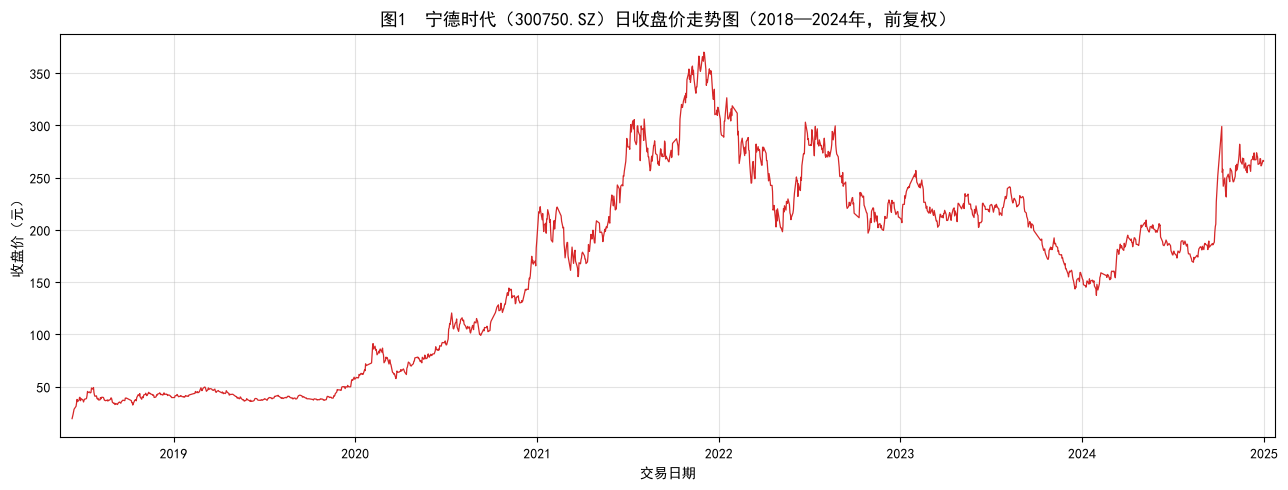

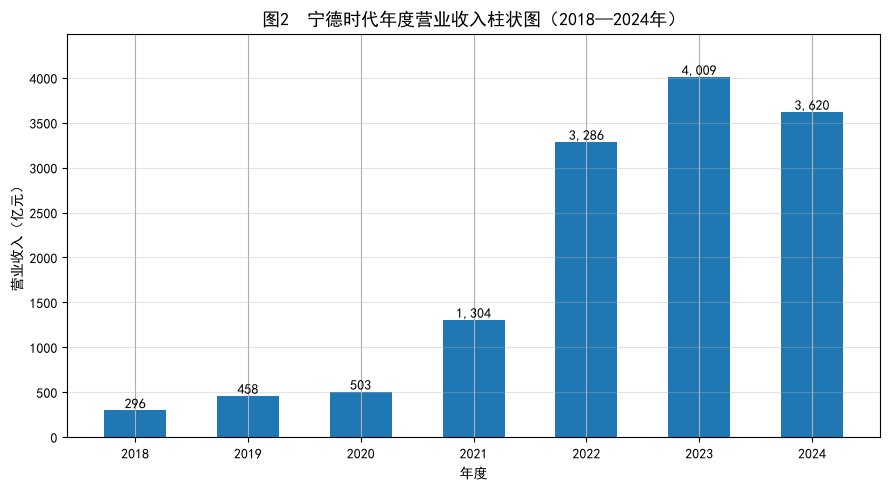

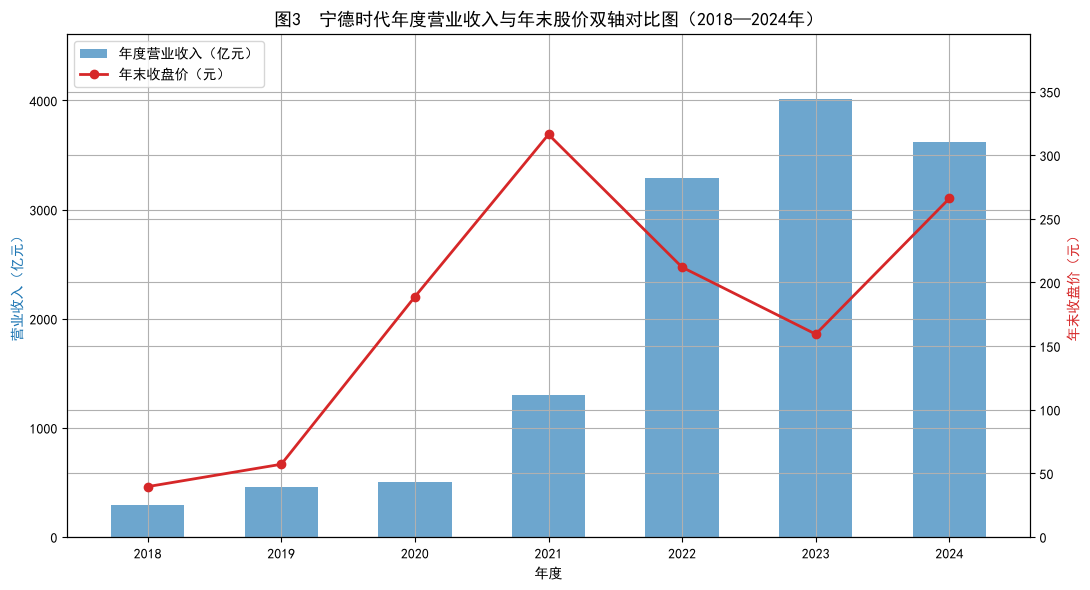

样本数量 n = 7（2018—2024年，共7个年度观测）
① 年度营业收入与年末收盘价的皮尔逊相关系数 r = 0.4550
② 营收同比增长率与年末股价涨跌幅的皮尔逊相关系数 r = -0.3861


,年度,营业收入(亿元),年末收盘价(元),营收同比增长(%),年末股价涨跌幅(%)
0,2018,296.11,39.55,NaN,NaN
1,2019,457.88,57.12,54.63,44.42
2,2020,503.19,188.78,9.90,230.50
3,2021,1303.56,316.30,159.06,67.55
4,2022,3285.94,211.95,152.07,-32.99
5,2023,4009.17,159.36,22.01,-24.81
6,2024,3620.13,266.00,-9.70,66.92


In [3]:
# ============================================================
# 第四部分：数据分析过程
# ============================================================
%matplotlib inline

# ---------- 基础数据表：年末收盘价 + 营业收入 + 变动率 ----------
year_end_close = daily.groupby(daily['trade_date'].dt.year)['qfq_close'].last()

summary = pd.DataFrame({'年度': [int(y) for y in year_end_close.index],
                        '年末收盘价(元)': np.round(year_end_close.values, 2)})
summary = (pd.merge(annual_revenue, summary, on='年度')
             .sort_values('年度')
             .reset_index(drop=True))
summary['营收同比增长(%)'] = summary['营业收入(亿元)'].pct_change().mul(100).round(2)
summary['年末股价涨跌幅(%)'] = summary['年末收盘价(元)'].pct_change().mul(100).round(2)

# ---------- 图1：日收盘价走势图 ----------
fig1, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(daily['trade_date'], daily['qfq_close'], color='#d62728', linewidth=0.9)
ax1.set_title('图1  宁德时代（300750.SZ）日收盘价走势图（2018—2024年，前复权）', fontsize=13)
ax1.set_xlabel('交易日期')
ax1.set_ylabel('收盘价（元）')
ax1.margins(x=0.01)
ax1.grid(True, alpha=0.35)
fig1.tight_layout()
plt.show()

# ---------- 图2：年度营业收入柱状图 ----------
fig2, ax2 = plt.subplots(figsize=(9, 5))
xlabels = summary['年度'].astype(str)
bars = ax2.bar(xlabels, summary['营业收入(亿元)'], color='#1f77b4', width=0.55)
for bar, val in zip(bars, summary['营业收入(亿元)']):
    ax2.annotate(f'{val:,.0f}',
                 (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 ha='center', va='bottom', fontsize=10)
ax2.set_title('图2  宁德时代年度营业收入柱状图（2018—2024年）', fontsize=13)
ax2.set_xlabel('年度')
ax2.set_ylabel('营业收入（亿元）')
ax2.set_ylim(0, summary['营业收入(亿元)'].max() * 1.12)
ax2.grid(True, axis='y', alpha=0.35)
fig2.tight_layout()
plt.show()

# ---------- 图3：营收与股价双轴对比图 ----------
fig3, ax3 = plt.subplots(figsize=(11, 6))
bars3 = ax3.bar(xlabels, summary['营业收入(亿元)'], color='#1f77b4',
                alpha=0.65, width=0.55, label='年度营业收入（亿元）')
ax3.set_xlabel('年度')
ax3.set_ylabel('营业收入（亿元）', color='#1f77b4')
ax3.set_ylim(0, summary['营业收入(亿元)'].max() * 1.15)

ax4 = ax3.twinx()
line4, = ax4.plot(xlabels, summary['年末收盘价(元)'], color='#d62728',
                  marker='o', linewidth=2, label='年末收盘价（元）')
ax4.set_ylabel('年末收盘价（元）', color='#d62728')
ax4.set_ylim(0, summary['年末收盘价(元)'].max() * 1.25)

ax3.set_title('图3  宁德时代年度营业收入与年末股价双轴对比图（2018—2024年）', fontsize=13)
ax3.legend(handles=[bars3, line4],
           labels=['年度营业收入（亿元）', '年末收盘价（元）'], loc='upper left')
fig3.tight_layout()
plt.show()

# ---------- 皮尔逊相关系数 ----------
r_price = summary['营业收入(亿元)'].corr(summary['年末收盘价(元)'], method='pearson')
r_growth = summary['营收同比增长(%)'].corr(summary['年末股价涨跌幅(%)'], method='pearson')
print('=' * 62)
print(f'样本数量 n = {len(summary)}（2018—2024年，共7个年度观测）')
print(f'① 年度营业收入与年末收盘价的皮尔逊相关系数 r = {r_price:.4f}')
print(f'② 营收同比增长率与年末股价涨跌幅的皮尔逊相关系数 r = {r_growth:.4f}')
print('=' * 62)

# ---------- 年度数据表 ----------
summary

## 4.1 结果解读与问题回答

**（1）日收盘价走势（图1）。** 宁德时代股价在样本期内呈现"单边上行—深度回调—企稳反弹"三个阶段：2018—2021年末收盘价由39.55元升至316.30元，其中2020年单年涨幅高达230.50%，2021年再涨67.55%；2022、2023年股价连续回落，年末收盘价分别下跌32.99%和24.81%；2024年股价大幅反弹66.92%，年末收于266.00元。需要说明的是，为消除2019—2024年间多次除权除息（尤其是2023年4月每10股转增8股）造成的除权缺口，以上价格均经前复权处理，以保证跨年度比较的客观性。

**（2）年度营业收入（图2）。** 2018—2023年营业收入由296.11亿元增至4009.17亿元，达到2018年的约13.5倍；除2020年增速回落至9.90%外，其余年份均保持高速扩张，2021年、2022年增速分别高达159.06%和152.07%，与新能源汽车渗透率快速提升的产业周期高度吻合。2024年营业收入为3620.13亿元，同比下降9.70%，为上市以来首次年度负增长，反映行业竞争加剧与产品价格下行的压力。

**（3）双轴对比（图3）。** 2018—2021年，营业收入与年末股价基本同向扩张，量价齐升；2022—2023年出现显著背离——营业收入连续两年创下历史新高，年末股价却持续走低，两年间股价累计下跌约五成；2024年则呈反向变动，营业收入首次下滑，股价反而大涨66.92%。

**（4）相关系数。** 年度营业收入与年末收盘价的皮尔逊相关系数为 **r = 0.4550**（n = 7），属于弱到中等程度的正相关。在显著性水平α = 0.05、自由度为5的条件下，双侧检验的临界值约为0.754，|r| = 0.4550 < 0.754，未通过显著性检验。作为补充，营收同比增长率与年末股价涨跌幅的相关系数为 **r = -0.3861**，呈弱负相关，表明股价的年度涨跌与当期营收增速并不同步，二级市场定价更多反映的是对未来增速的预期，而非当期业绩的绝对水平。

**（5）对研究问题的回答。** 综合上述结果，本研究的判断是：**营业收入的变化对宁德时代股价走势具有方向性的、但并不充分的支撑作用。** 一方面，样本期内两者长期趋势总体一致、线性相关为正（r = 0.4550），且营收由296.11亿元扩张至3620.13亿元的过程伴随着股价中枢的系统性抬升，说明经营规模的持续放大确实构成股价上行的基本面底座，营收下滑的年份（2024年）也对应着公司经营层面的现实压力；另一方面，相关系数未通过显著性检验，2022—2023年"增收不增价"与2024年"减收却大涨"的典型背离表明，营收水平既非股价上涨的充分条件，也非逐年度一一对应的直接驱动力。因此，营收对股价的支撑是长期趋势意义上、经由市场预期传导的间接支撑，须与估值端因素共同解释股价波动。

# 第五部分：研究结论与经验总结

## 研究结论

1. **总体正相关、支撑作用有限。** 2018—2024年宁德时代年度营业收入与年末收盘价的皮尔逊相关系数为0.4550，呈弱正相关且未通过显著性检验（临界值约0.754）。营业收入的增长对股价存在方向性支撑，但该支撑并不充分，营收并非决定股价走势的唯一变量。
2. **股价定价边际变化与未来预期。** 2022—2023年公司营业收入连续创下新高而股价持续回落，2024年营业收入首次下滑而股价上涨66.92%，说明二级市场更关注营收的边际变化方向与可持续性，而非收入的绝对规模；行业景气度、无风险利率与市场风险偏好等估值因素会在中短期内主导股价。
3. **基本面是股价长期基石。** 从完整样本看，营业收入由2018年的296.11亿元最高增至2023年的4009.17亿元，年末股价同期由39.55元升至266.00元，长期趋势总体一致，印证了经营业绩对股价的长期支撑作用，也解释了二者相关系数为正的原因。

## 经验总结

1. **接口认证与权限规划。** 通过本次实践掌握了Tushare Pro的token认证与`pro.pro_api`调用流程，也认识到不同接口对应不同权限等级：日线行情接口可直接调用，利润表等财务接口则对token积分有更高要求。实际分析前应先确认数据源的可用边界，并在代码中预留容错与回退路径，保证研究可复现。
2. **数据清洗与口径意识。** 财务数据必须先统一口径再进入分析——本次严格筛选"报告期为12月31日的合并报表"，避免季报、中报与年报混用造成的重复与偏差（接口返回结果中确有重复记录，需按报告期去重）；行情数据则需完成日期转换、升序排序、去重与缺失值处理。按年度循环调用接口，可有效规避单次返回条数的限制。
3. **复权处理至关重要。** 除权除息会使未复权价格序列出现虚假断层，2023年4月的每10股转增8股若不处理，将使2023年股价表面上"腰斩"，进而严重误导读图与相关性检验。利用昨收价与前收盘价的比值构建复权因子，是一种无需额外接口权限、低成本实现价格可比的有效方法。
4. **可视化与统计方法。** 本次巩固了Matplotlib中文环境配置（字体与负号）、双轴图绘制与图例合并等技能，练习了皮尔逊相关系数的计算与显著性判断；同时体会到小样本（n = 7）下相关系数的局限，统计量必须结合经济含义与显著性水平谨慎解读。
5. **方法论反思。** 数据分析的价值不在于算出一个数值，而在于通过口径设计、图表呈现与多角度相互印证，形成边界清晰、证据充分的回答。本次分析再次说明：相关不等于因果，任何统计结论都应交代前提、边界与可能的替代解释。